# Function Approximation with a Neural Network

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

/Users/dhairyasibal/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## 2. Load the data

In [2]:
df = pd.read_csv("data_group6.csv")
df.head()

,sr_no,x,y,z,f
0,0,-17.344168,2.710483,65.495075,-0.552103
1,1,-38.653767,11.337382,-38.323410,0.780392
2,2,-49.050172,-6.540692,29.545560,-0.068591
3,3,69.601288,-93.890275,-19.824298,-0.780490
4,4,-50.763835,-72.135648,70.136871,0.865525


In [3]:
# sr_no is only a row number, so we remove it
df = df.drop(columns=["sr_no"])
df.shape

(30000, 4)

In [4]:
df.describe()

,x,y,z,f
count,30000.000000,30000.000000,30000.000000,30000.000000
mean,-0.049228,-0.027419,0.110550,0.016262
std,57.823919,57.840689,57.559747,0.712582
min,-100.096942,-100.097766,-100.096170,-0.999994
25%,-49.974890,-50.050830,-49.499659,-0.690801
50%,-0.392347,0.089784,0.065617,0.021838
75%,49.943560,50.040590,50.105097,0.719228
max,100.085753,100.098289,100.097266,3.311395


In [5]:
df.isna().sum()

x    0
y    0
z    0
f    0
dtype: int64

## 3. Look at the data

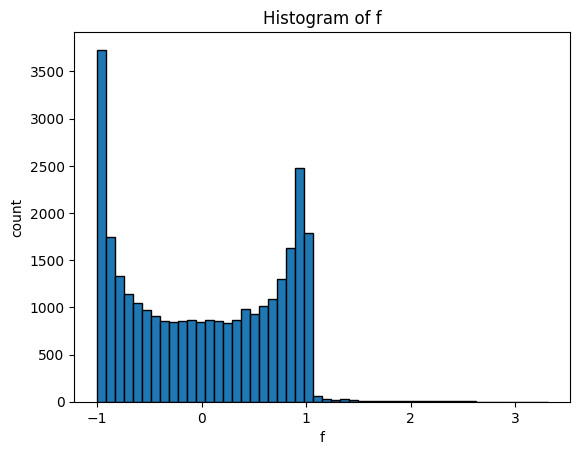

In [6]:
plt.hist(df["f"], bins=50, edgecolor="black")
plt.xlabel("f")
plt.ylabel("count")
plt.title("Histogram of f")
plt.show()

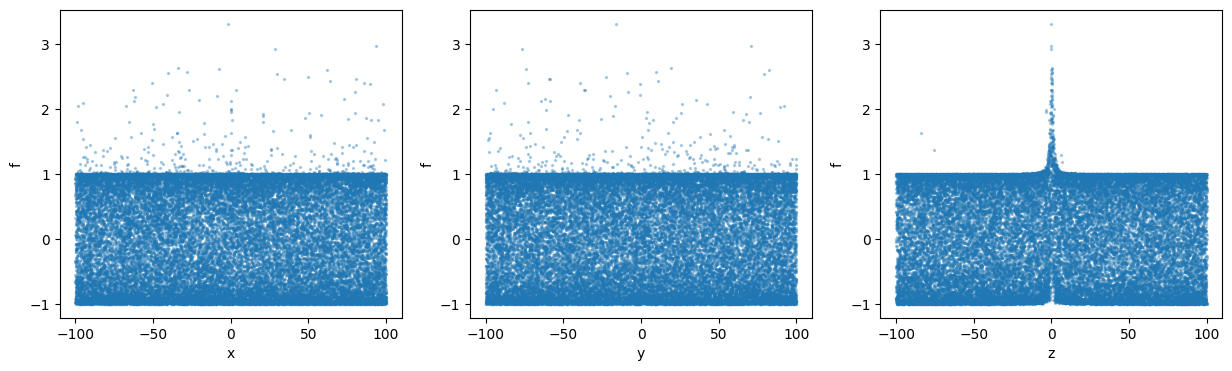

In [7]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.scatter(df["x"], df["f"], s=2, alpha=0.3)
plt.xlabel("x")
plt.ylabel("f")

plt.subplot(1, 3, 2)
plt.scatter(df["y"], df["f"], s=2, alpha=0.3)
plt.xlabel("y")
plt.ylabel("f")

plt.subplot(1, 3, 3)
plt.scatter(df["z"], df["f"], s=2, alpha=0.3)
plt.xlabel("z")
plt.ylabel("f")

plt.show()

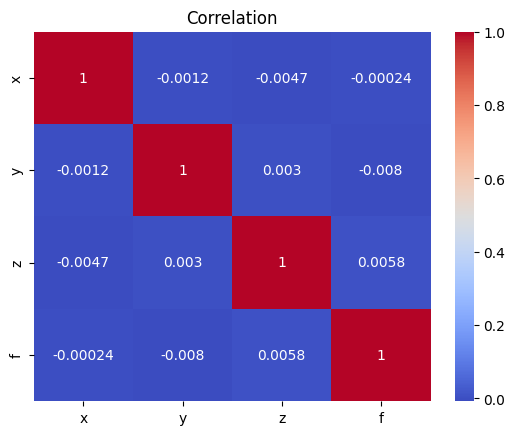

In [8]:
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation")
plt.show()

## 4. Look for a useful new input

In [36]:
# correlation of f with some new columns (closer to 1 is better)
print("sin(x)      :", np.corrcoef(np.sin(df["x"]), df["f"])[0, 1])
print("sin(x*y)    :", np.corrcoef(np.sin(df["x"] * df["y"]), df["f"])[0, 1])
print("sin(x**2+z) :", np.corrcoef(np.sin(df["x"]**2 + df["z"]), df["f"])[0, 1])
print("sin(y**2+z) :", np.corrcoef(np.sin(df["y"]**2 + df["z"]), df["f"])[0, 1])

print("x             :", np.corrcoef(df["x"], df["f"])[0, 1])
print("y             :", np.corrcoef(df["y"], df["f"])[0, 1])
print("z             :", np.corrcoef(df["z"], df["f"])[0, 1])

print("x_squared     :", np.corrcoef(df["x"]**2, df["f"])[0, 1])
print("y_squared     :", np.corrcoef(df["y"]**2, df["f"])[0, 1])
print("z_squared     :", np.corrcoef(df["z"]**2, df["f"])[0, 1])

print("x_plus_y      :", np.corrcoef(df["x"] + df["y"], df["f"])[0, 1])
print("y_plus_z      :", np.corrcoef(df["y"] + df["z"], df["f"])[0, 1])

print("x_times_y     :", np.corrcoef(df["x"] * df["y"], df["f"])[0, 1])
print("y_times_z     :", np.corrcoef(df["y"] * df["z"], df["f"])[0, 1])

print("sin_x         :", np.corrcoef(np.sin(df["x"]), df["f"])[0, 1])
print("sin_y         :", np.corrcoef(np.sin(df["y"]), df["f"])[0, 1])
print("sin_z         :", np.corrcoef(np.sin(df["z"]), df["f"])[0, 1])

sin(x)      : -0.0009590564512469898
sin(x*y)    : -0.006432442679669551
sin(x**2+z) : -0.009709552435753804
sin(y**2+z) : 0.9895124416142537
x             : -0.00023749203279671926
y             : -0.007981000389043542
z             : 0.005766255291708105
x_squared     : -0.002458413667025619
y_squared     : -0.0026585455936258564
z_squared     : -0.04000342434730827
x_plus_y      : -0.005815599716619203
y_plus_z      : -0.00158737532158257
x_times_y     : 0.0026741301192423485
y_times_z     : 0.0003613114410313081
sin_x         : -0.0009590564512469898
sin_y         : -0.0005668047882646507
sin_z         : 0.011129830561138043


## 5. Split the data

In [10]:
train, test = train_test_split(df, test_size=0.15, random_state=42)
train, val = train_test_split(train, test_size=0.15 / 0.85, random_state=42)

print(len(train), len(val), len(test))

21000 4500 4500


## 6. Model A: inputs x, y, z only

In [11]:
X_train = train[["x", "y", "z"]].values
X_val = val[["x", "y", "z"]].values
X_test = test[["x", "y", "z"]].values

In [12]:
scaler_x = StandardScaler()
X_train_s = scaler_x.fit_transform(X_train)
X_val_s = scaler_x.transform(X_val)
X_test_s = scaler_x.transform(X_test)

In [13]:
scaler_y = StandardScaler()
y_train_s = scaler_y.fit_transform(train[["f"]])
y_val_s = scaler_y.transform(val[["f"]])

In [14]:
model_a = keras.Sequential([
    keras.Input(shape=(3,)),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(1),
])
model_a.compile(optimizer="adam", loss="mse")

In [15]:
stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)

history_a = model_a.fit(
    X_train_s, y_train_s,
    validation_data=(X_val_s, y_val_s),
    epochs=100, batch_size=128,
    callbacks=[stop], verbose=0,
)

In [16]:
pred_a = scaler_y.inverse_transform(model_a.predict(X_val_s)).ravel()

print("MSE :", mean_squared_error(val["f"], pred_a))
print("RMSE:", np.sqrt(mean_squared_error(val["f"], pred_a)))
print("MAE :", mean_absolute_error(val["f"], pred_a))
print("R2  :", r2_score(val["f"], pred_a))

141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 244us/step
MSE : 0.49847338353408505
RMSE: 0.706026475094302
MAE : 0.6285047864069889
R2  : 0.008758100709768457


## 7. Model B: add the new input sin(y² + z)

In [17]:
X_train2 = np.column_stack([train["x"], train["y"], train["z"], np.sin(train["y"]**2 + train["z"])])
X_val2 = np.column_stack([val["x"], val["y"], val["z"], np.sin(val["y"]**2 + val["z"])])
X_test2 = np.column_stack([test["x"], test["y"], test["z"], np.sin(test["y"]**2 + test["z"])])

In [18]:
scaler_x2 = StandardScaler()
X_train2_s = scaler_x2.fit_transform(X_train2)
X_val2_s = scaler_x2.transform(X_val2)
X_test2_s = scaler_x2.transform(X_test2)

In [19]:
model_b = keras.Sequential([
    keras.Input(shape=(4,)),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(1),
])
model_b.compile(optimizer="adam", loss="mse")

In [20]:
history_b = model_b.fit(
    X_train2_s, y_train_s,
    validation_data=(X_val2_s, y_val_s),
    epochs=100, batch_size=128,
    callbacks=[stop], verbose=0,
)

In [21]:
pred_b = scaler_y.inverse_transform(model_b.predict(X_val2_s)).ravel()

print("MSE :", mean_squared_error(val["f"], pred_b))
print("RMSE:", np.sqrt(mean_squared_error(val["f"], pred_b)))
print("MAE :", mean_absolute_error(val["f"], pred_b))
print("R2  :", r2_score(val["f"], pred_b))

141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 227us/step
MSE : 0.005072531125294158
RMSE: 0.07122170403250794
MAE : 0.02073814849926027
R2  : 0.9899129912389764


## 8. Model C: a bigger network (with the new input)

In [31]:
model_c = keras.Sequential([
    keras.Input(shape=(4,)),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(1)
])
model_c.compile(optimizer="adam", loss="mse")

In [32]:
history_c = model_c.fit(
    X_train2_s, y_train_s,
    validation_data=(X_val2_s, y_val_s),
    epochs=100, batch_size=128,
    callbacks=[stop], verbose=0,
)

In [33]:
pred_c = scaler_y.inverse_transform(model_c.predict(X_val2_s)).ravel()

print("MSE :", mean_squared_error(val["f"], pred_c))
print("RMSE:", np.sqrt(mean_squared_error(val["f"], pred_c)))
print("MAE :", mean_absolute_error(val["f"], pred_c))
print("R2  :", r2_score(val["f"], pred_c))

141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 307us/step
MSE : 0.005754591935286257
RMSE: 0.0758590267225085
MAE : 0.02101959760858863
R2  : 0.9885566755859024


## 9. Compare the models (validation)

In [25]:
print("Model A R2:", r2_score(val["f"], pred_a))
print("Model B R2:", r2_score(val["f"], pred_b))
print("Model C R2:", r2_score(val["f"], pred_c))

Model A R2: 0.008758100709768457
Model B R2: 0.9899129912389764
Model C R2: 0.9890904745426141


## 10. Loss curves

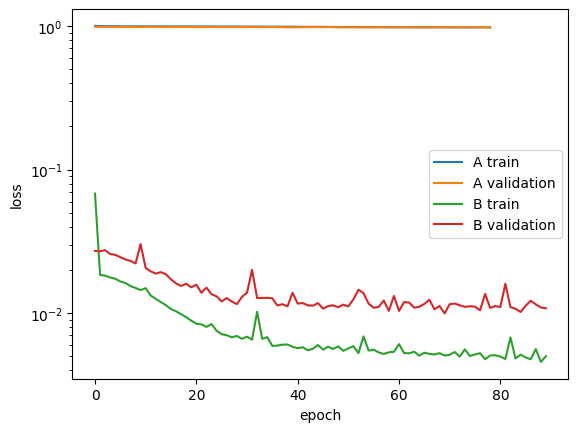

In [26]:
plt.plot(history_a.history["loss"], label="A train")
plt.plot(history_a.history["val_loss"], label="A validation")
plt.plot(history_b.history["loss"], label="B train")
plt.plot(history_b.history["val_loss"], label="B validation")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

## 11. Final test result (use the best model)

In [27]:
# change model_b to model_c below if C had the best R2 on validation
best_model = model_b

pred_test = scaler_y.inverse_transform(best_model.predict(X_test2_s)).ravel()

print("MSE :", mean_squared_error(test["f"], pred_test))
print("RMSE:", np.sqrt(mean_squared_error(test["f"], pred_test)))
print("MAE :", mean_absolute_error(test["f"], pred_test))
print("R2  :", r2_score(test["f"], pred_test))

141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 181us/step
MSE : 0.004574825347239567
RMSE: 0.06763745520966595
MAE : 0.020641069441352224
R2  : 0.9909656591847077


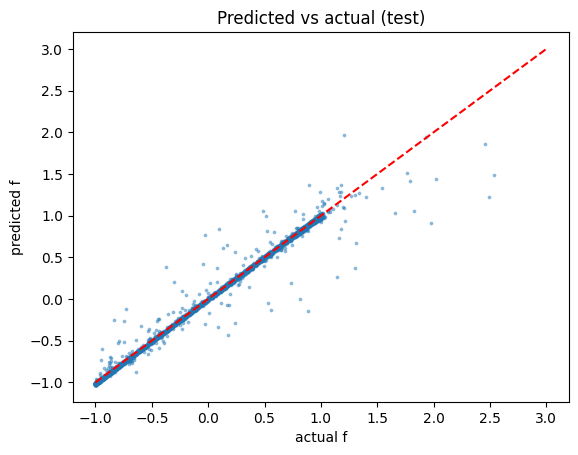

In [28]:
plt.scatter(test["f"], pred_test, s=3, alpha=0.4)
plt.plot([-1, 3], [-1, 3], "r--")
plt.xlabel("actual f")
plt.ylabel("predicted f")
plt.title("Predicted vs actual (test)")
plt.show()

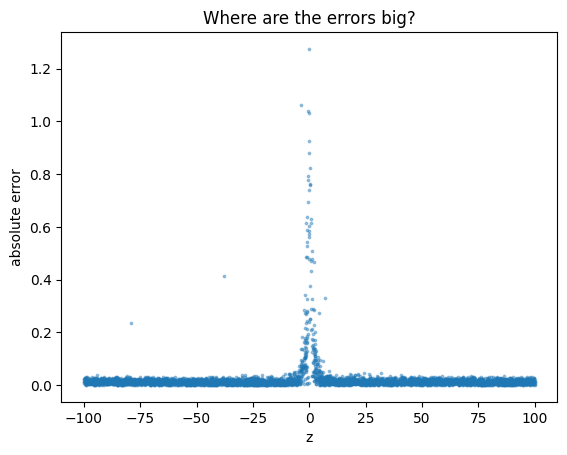

In [29]:
error = test["f"] - pred_test

plt.scatter(test["z"], abs(error), s=3, alpha=0.4)
plt.xlabel("z")
plt.ylabel("absolute error")
plt.title("Where are the errors big?")
plt.show()

## 12. Bonus: the exact function

In [45]:
x = df["x"]
y = df["y"]
z = df["z"]

formula = np.sin(y**2 +z +x) 

print("biggest difference:", abs(df["f"] - formula).max())
print("R2:", r2_score(df["f"], formula))

biggest difference: 3.8888477323931587
R2: -0.9918590567668688
